In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")
%matplotlib inline

In [2]:
# Load dataset
diabetes_data = pd.read_csv("diabetes - diabetes.csv")
diabetes_data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# Dataset information and summary
diabetes_data.info()
display(diabetes_data.describe().T)
print("Dataset shape:", diabetes_data.shape)
print("\\nMissing values:\\n", diabetes_data.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


Dataset shape: (768, 9)
\nMissing values:\n Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [4]:
# Replace impossible zero values with NaN in these medical measurement columns
diabetes_data_copy = diabetes_data.copy()
zero_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
diabetes_data_copy[zero_columns] = diabetes_data_copy[zero_columns].replace(0, np.nan)

print("Missing values after replacing zeros:")
display(diabetes_data_copy.isnull().sum())

Missing values after replacing zeros:


Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

In [5]:
# Fill missing values using the median
for column in zero_columns:
    diabetes_data_copy[column] = diabetes_data_copy[column].fillna(diabetes_data_copy[column].median())

diabetes_data_copy.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

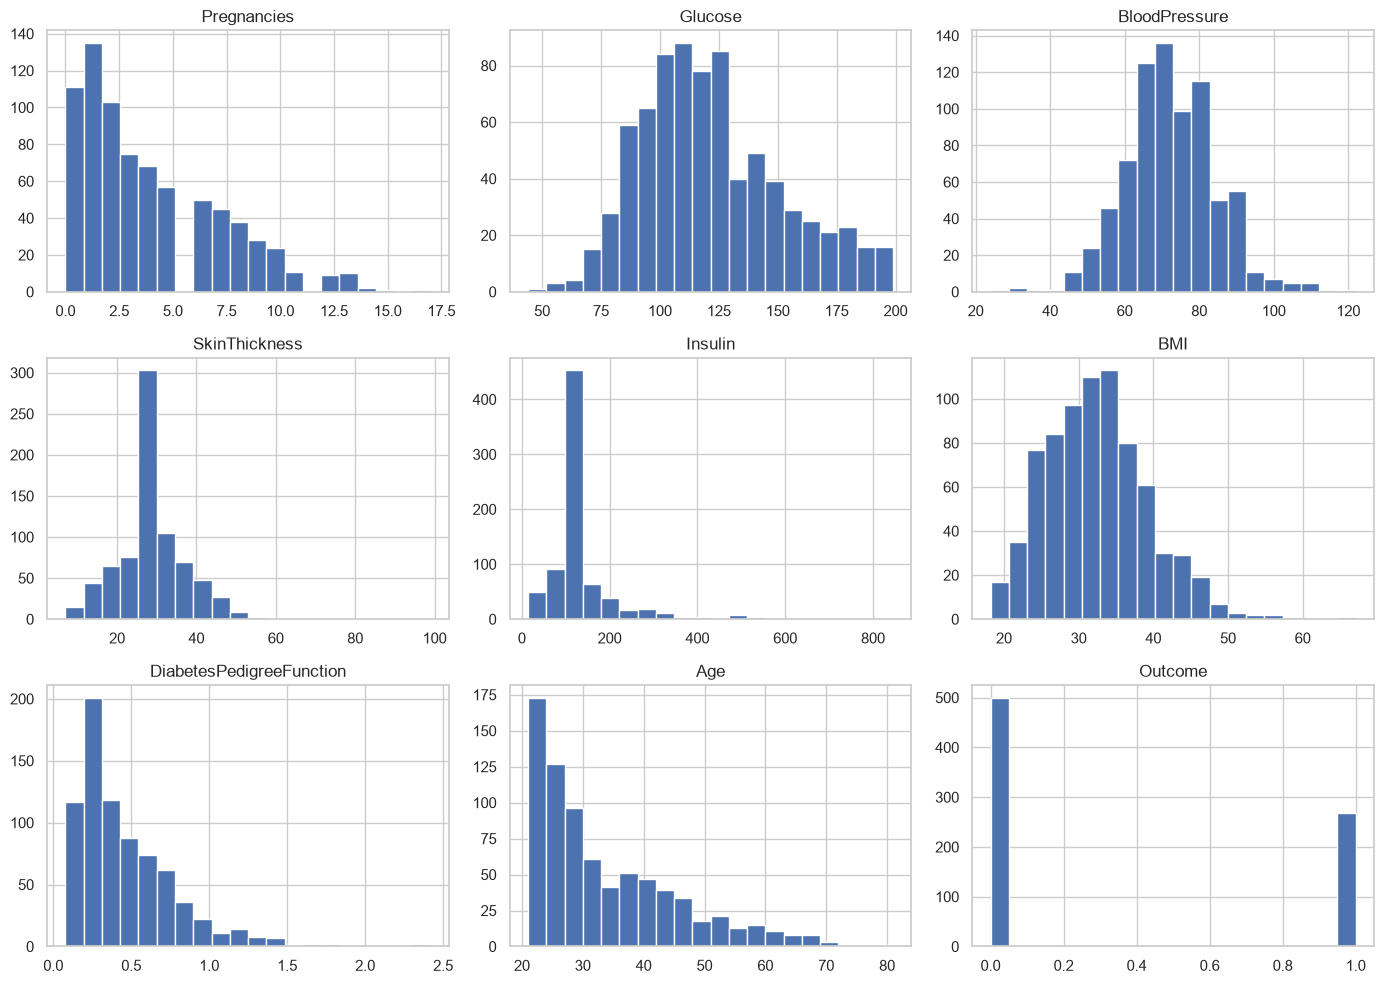

In [6]:
# Histograms
diabetes_data_copy.hist(figsize=(14, 10), bins=20)
plt.tight_layout()
plt.show()

Outcome
0    500
1    268
Name: count, dtype: int64


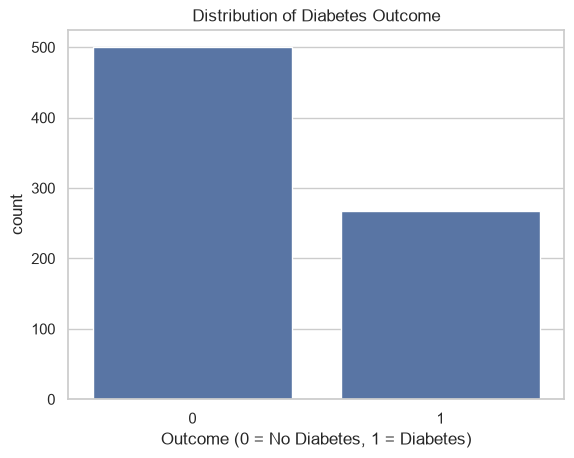

In [7]:
# Count of diabetic and non-diabetic cases
print(diabetes_data_copy["Outcome"].value_counts())
sns.countplot(data=diabetes_data_copy, x="Outcome")
plt.title("Distribution of Diabetes Outcome")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.show()

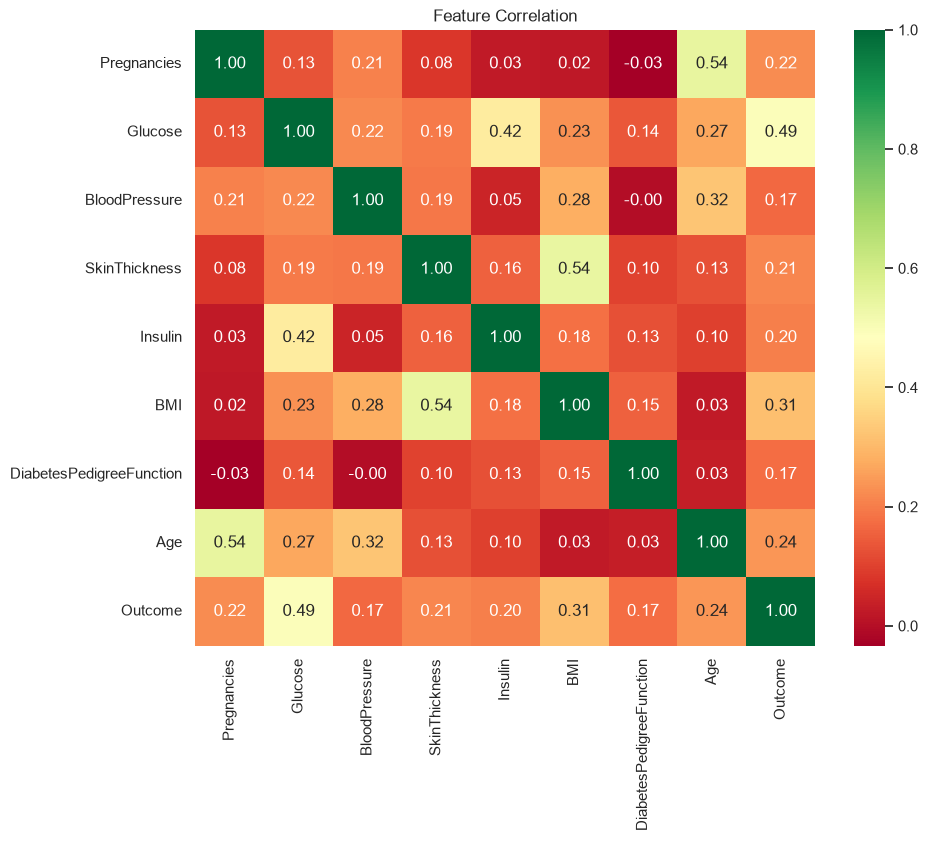

In [8]:
# Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(diabetes_data_copy.corr(numeric_only=True), annot=True, cmap="RdYlGn", fmt=".2f")
plt.title("Feature Correlation")
plt.show()

In [9]:
# Separate input features (X) and target (y)
X = diabetes_data_copy.drop("Outcome", axis=1)
y = diabetes_data_copy["Outcome"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=1/3, random_state=42, stratify=y
)

In [10]:
# Standardize features (fit only on training data to avoid data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [11]:
# Find the best K value from 1 to 14
train_scores = []
test_scores = []

for k in range(1, 15):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    train_scores.append(model.score(X_train_scaled, y_train))
    test_scores.append(model.score(X_test_scaled, y_test))

best_k = int(np.argmax(test_scores)) + 1
print(f"Best K: {best_k}")
print(f"Best test accuracy: {max(test_scores) * 100:.2f}%")

Best K: 11
Best test accuracy: 75.78%


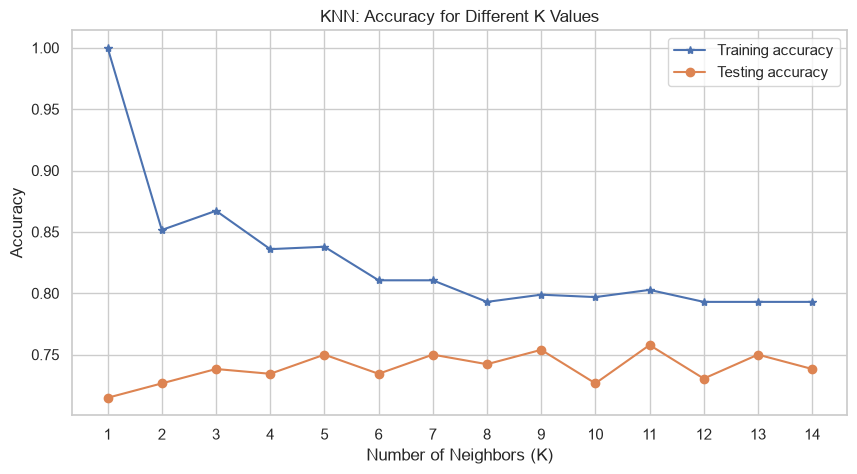

In [12]:
# Compare training and testing accuracy
plt.figure(figsize=(10, 5))
plt.plot(range(1, 15), train_scores, marker="*", label="Training accuracy")
plt.plot(range(1, 15), test_scores, marker="o", label="Testing accuracy")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")
plt.title("KNN: Accuracy for Different K Values")
plt.xticks(range(1, 15))
plt.legend()
plt.show()

In [13]:
# Train final KNN model using the best K
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\\nClassification report:\\n")
print(classification_report(y_test, y_pred))

Accuracy: 0.7578125
\nClassification report:\n
              precision    recall  f1-score   support

           0       0.80      0.84      0.82       167
           1       0.67      0.60      0.63        89

    accuracy                           0.76       256
   macro avg       0.73      0.72      0.73       256
weighted avg       0.75      0.76      0.75       256



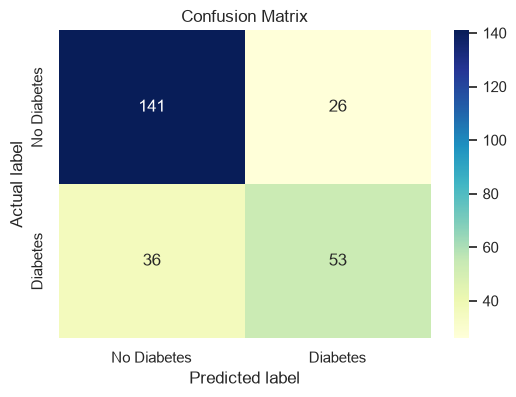

In [14]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="YlGnBu",
            xticklabels=["No Diabetes", "Diabetes"],
            yticklabels=["No Diabetes", "Diabetes"])
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Confusion Matrix")
plt.show()

In [15]:
# Example input: Pregnancies, Glucose, BloodPressure, SkinThickness,
# Insulin, BMI, DiabetesPedigreeFunction, Age
new_patient = pd.DataFrame([{
    "Pregnancies": 2,
    "Glucose": 120,
    "BloodPressure": 70,
    "SkinThickness": 20,
    "Insulin": 79,
    "BMI": 25.0,
    "DiabetesPedigreeFunction": 0.5,
    "Age": 30
}])

new_patient_scaled = scaler.transform(new_patient)
prediction = knn.predict(new_patient_scaled)[0]

print("Prediction:", "Diabetes" if prediction == 1 else "No Diabetes")

Prediction: No Diabetes
